# Ray Serve: model multiplexing

One deployment serves many models: @serve.multiplexed loads a model by id on demand and keeps up to two per replica.

**When to use it.** Many small per-customer or per-language models that do not each justify a dedicated replica.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The builder lists a node in this graph in its *Experimental* section, so the node may change in later releases of the builder. The generated code ran on Ray 2.55.1.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

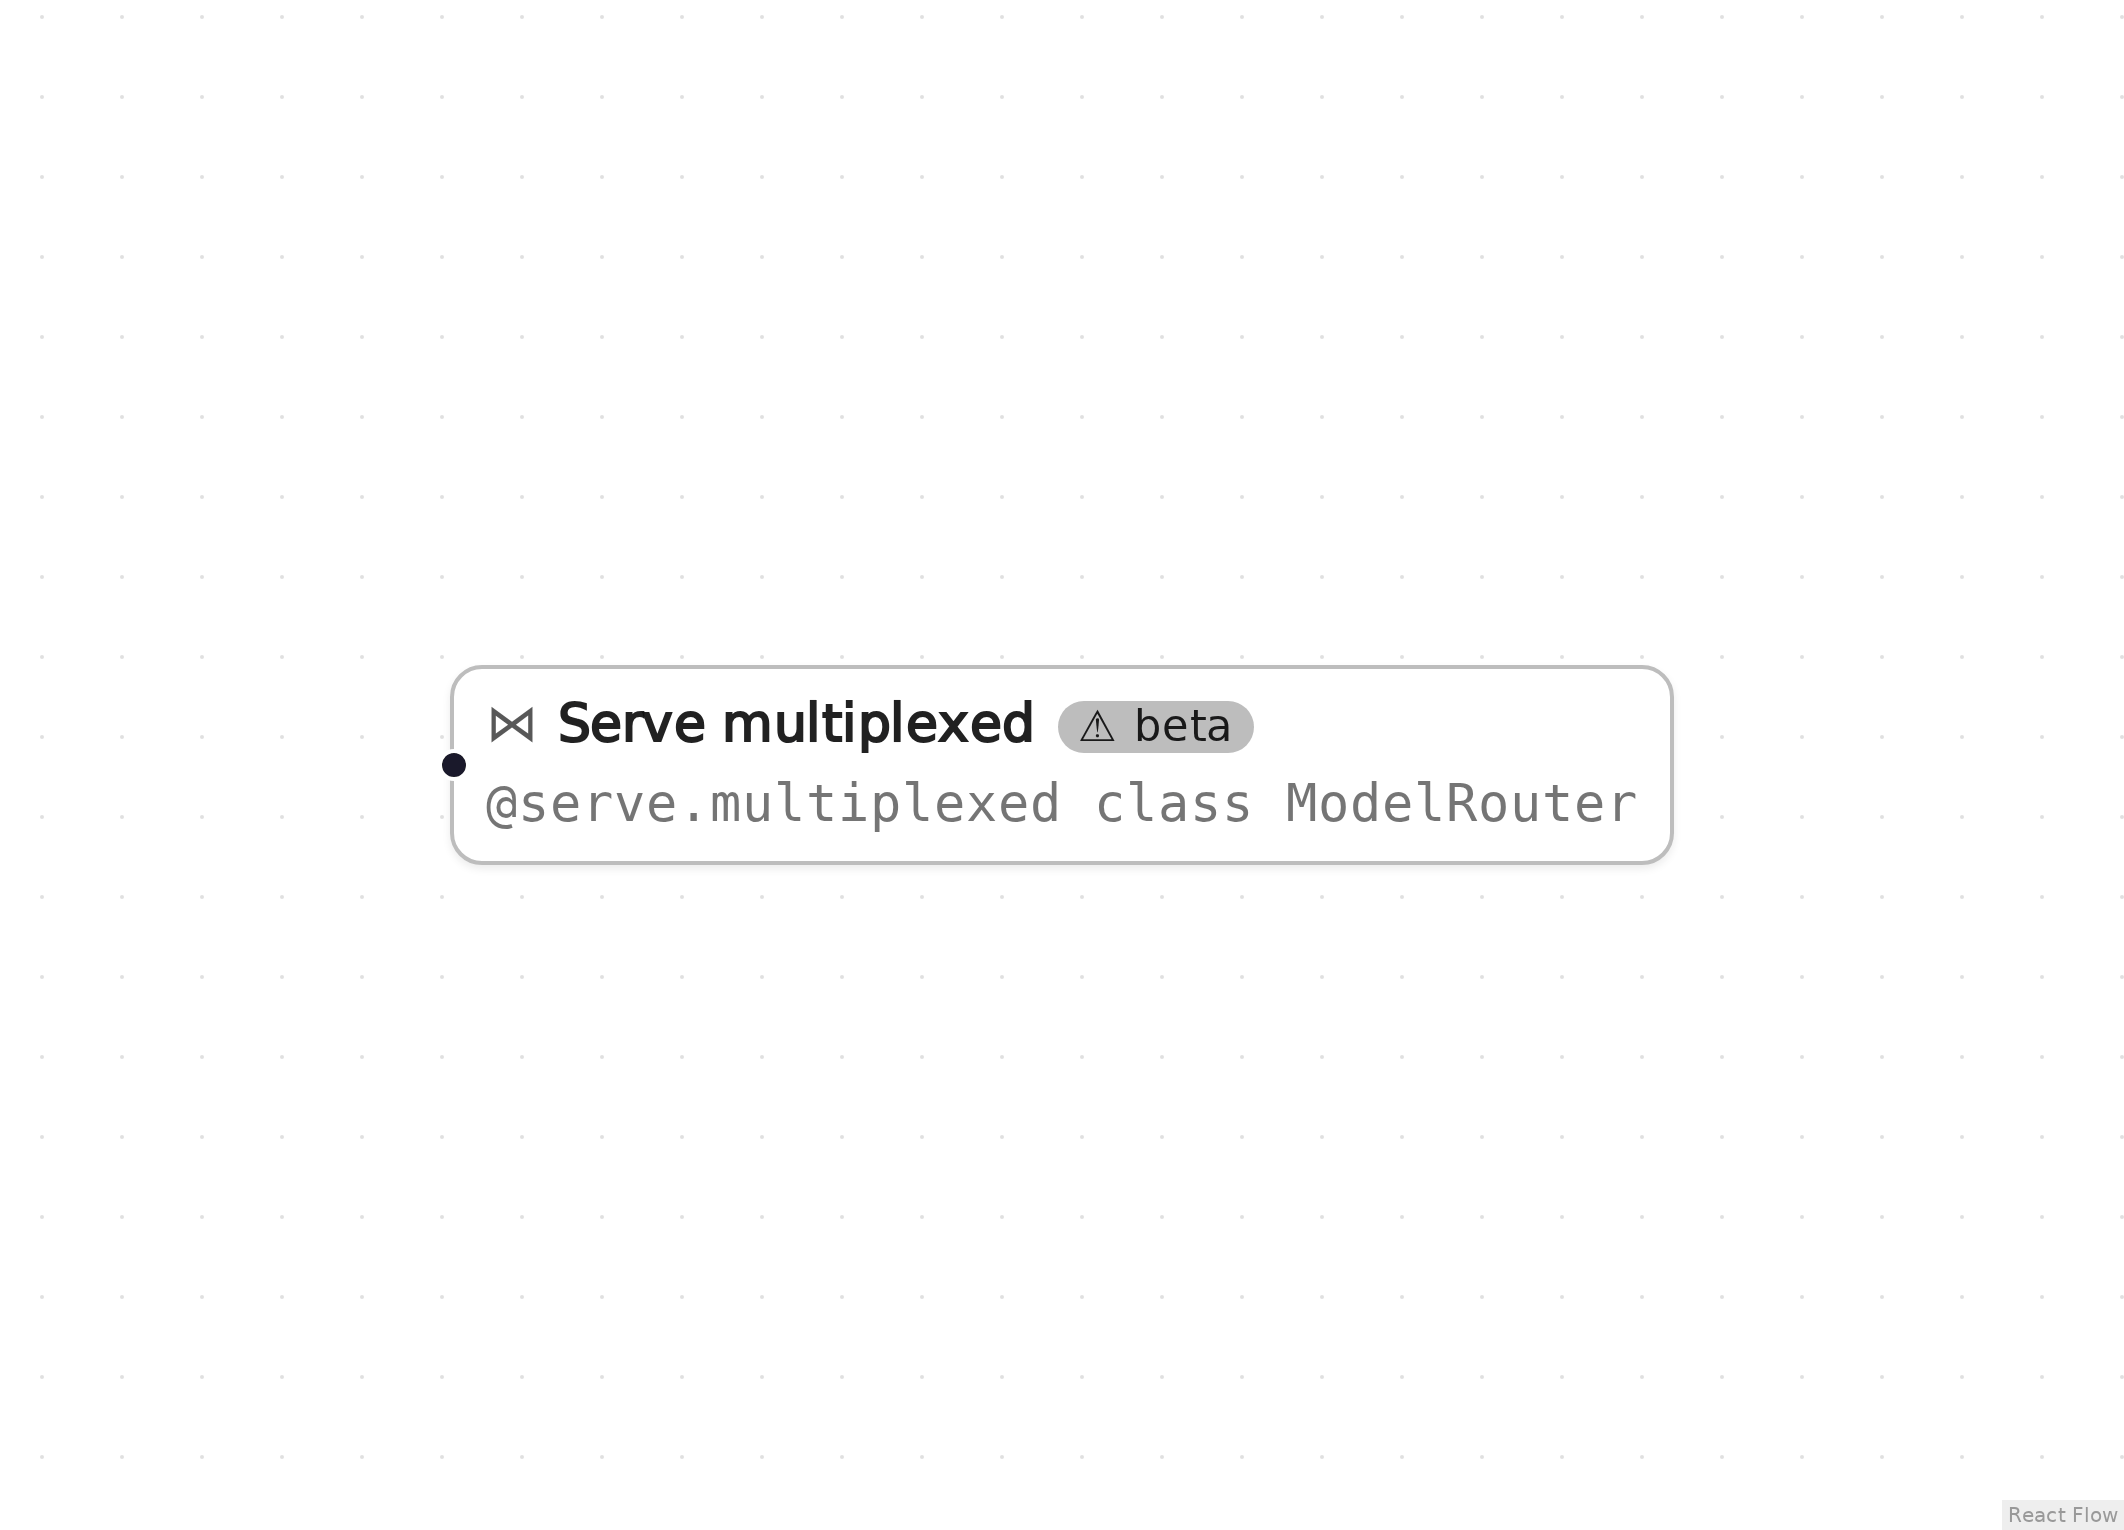

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
# The ModelRouter class is written by the builder from the node's settings.
from ray import serve

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray

if not ray.is_initialized():
    ray.init()

@serve.deployment
class ModelRouter:
    @serve.multiplexed(max_num_models_per_replica=2)
    async def get_model(self, model_id: str):
        return {"name": model_id}

    async def __call__(self, request):
        model_id = serve.get_multiplexed_model_id()
        model = await self.get_model(model_id)
        return model["name"]

_deploy_n1 = ModelRouter.bind()
serve.run(_deploy_n1)

DeploymentHandle(deployment='ModelRouter')

## Check the result

The cell below checks that the generated code did what the graph describes. A Jupyter kernel already runs an asyncio event loop, so this cell awaits the Serve responses; in a plain Python script you would call `.result()` on them instead.

In [4]:
handle = serve.get_app_handle("default")
a = await handle.options(multiplexed_model_id="model-a").remote("ping")
b = await handle.options(multiplexed_model_id="model-b").remote("ping")
assert (a, b) == ("model-a", "model-b"), (a, b)
print("served by", a, "and", b)

served by model-a and model-b


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Serve multiplexed (beta)** (node `n1`, lines 9–18 and 20–21)

```python
@serve.deployment
class ModelRouter:
    @serve.multiplexed(max_num_models_per_replica=2)
    async def get_model(self, model_id: str):
        return {"name": model_id}

    async def __call__(self, request):
        model_id = serve.get_multiplexed_model_id()
        model = await self.get_model(model_id)
        return model["name"]
...
_deploy_n1 = ModelRouter.bind()
serve.run(_deploy_n1)
```

get_model is the loader decorated with @serve.multiplexed(max_num_models_per_replica=2); __call__ reads the request's model id with serve.get_multiplexed_model_id() and awaits the cached model.

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [5]:
from ray import serve

serve.shutdown()
ray.shutdown()